# Exposure Sensitivity & Power BI Model

## tl;dr

- Local-authority vehicle miles cover 99.98% of collisions and support absolute risk rates.
- The AADF 100-metre sample covers about 11% of numbered-road collisions, while the Counted-only sample covers about 3%; both are therefore limited to sensitivity diagnostics.
- Injury-based reporting adjustment raises the KSI rate by 6.0% in 2021 and 2.1% in 2025.
- The 2025 Spearman correlation between raw and adjusted local-authority risk ranks is about 0.991: the broad spatial pattern is stable, although metric levels change.

## Context & Methods

### Key Assumptions

- Only DfT annual vehicle miles are used as the denominator for absolute risk rates.
- Adjusted expected KSI adds the DfT probability-based serious-injury estimate to fatal collisions.
- AADF analysis compares sample coverage under same-year, same-road, and distance-threshold rules.
- AADF geometry represents count points, so it is not treated as full road-link exposure.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
ROOT=Path.cwd()
plt.rcParams.update({'figure.figsize':(9,5),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2,'font.size':10})
BLUE='#2563EB'; ORANGE='#D97706'; GREY='#6B7280'

## Data

In [2]:
risk=pd.read_parquet(ROOT/'data/powerbi/fact_local_authority_year_risk.parquet')
sensitivity=pd.read_parquet(ROOT/'data/powerbi/fact_exposure_sensitivity.parquet')
{'risk_rows':len(risk),'sensitivity_rows':len(sensitivity),'years':sorted(risk.collision_year.unique())}

{'risk_rows': 1038,
 'sensitivity_rows': 20,
 'years': [np.int64(2021),
  np.int64(2022),
  np.int64(2023),
  np.int64(2024),
  np.int64(2025)]}

## Results

### 1. Raw vs adjusted KSI rate

In [3]:
covered=risk[risk.exposure_available]
annual=covered.groupby('collision_year').agg(raw_ksi=('raw_ksi','sum'),adjusted_ksi=('adjusted_expected_ksi','sum'),vehicle_miles=('annual_vehicle_miles','sum')).reset_index()
annual['raw_rate']=annual.raw_ksi/annual.vehicle_miles*1e9
annual['adjusted_rate']=annual.adjusted_ksi/annual.vehicle_miles*1e9
annual['adjustment_pct']=(annual.adjusted_rate/annual.raw_rate-1)*100
annual.round(2)

,collision_year,raw_ksi,adjusted_ksi,vehicle_miles,raw_rate,adjusted_rate,adjustment_pct
0,2021,22758,24132.08,3.057740e+11,74.43,78.92,6.04
1,2022,24935,26229.33,3.316686e+11,75.18,79.08,5.19
2,2023,24960,26166.02,3.362156e+11,74.24,77.83,4.83
3,2024,25069,26195.03,3.361762e+11,74.57,77.92,4.49
4,2025,26644,27195.78,3.438690e+11,77.48,79.09,2.07


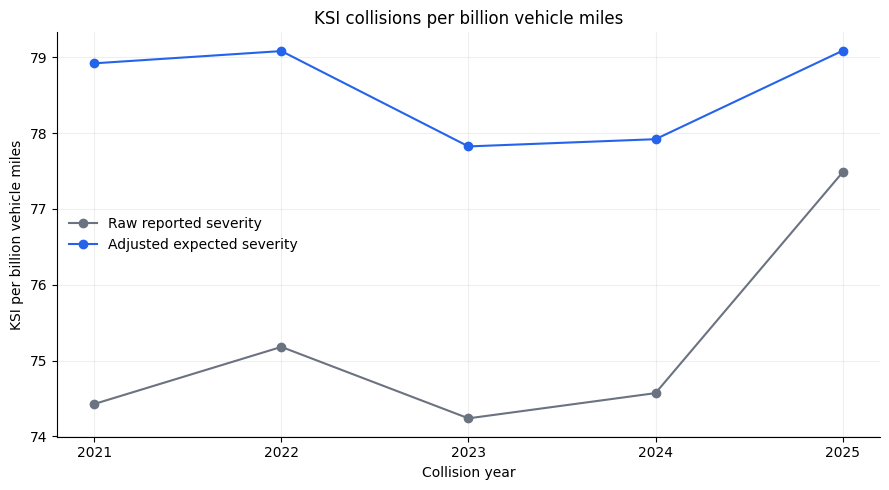

In [4]:
ax=annual.plot(x='collision_year',y=['raw_rate','adjusted_rate'],marker='o',color=[GREY,BLUE])
ax.set(title='KSI collisions per billion vehicle miles',xlabel='Collision year',ylabel='KSI per billion vehicle miles',xticks=annual.collision_year)
ax.legend(['Raw reported severity','Adjusted expected severity'],frameon=False)
plt.tight_layout(); plt.show()

### 2. Exposure scenario coverage

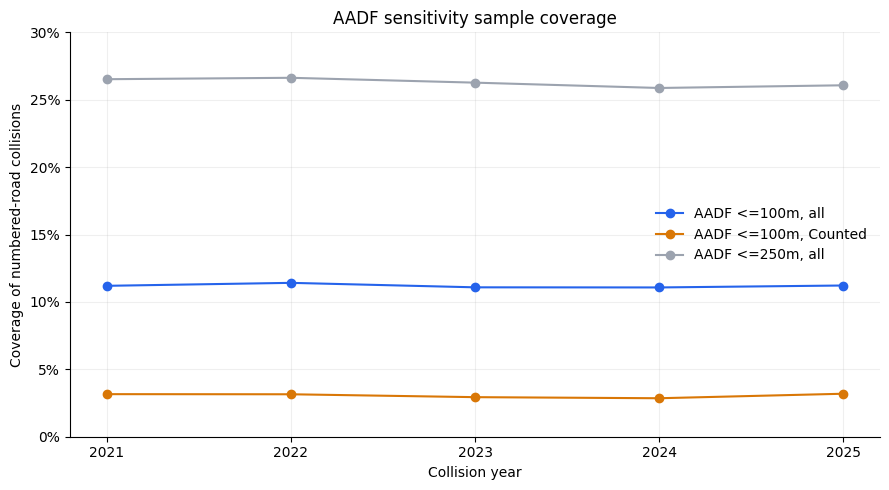

In [5]:
plot=sensitivity[sensitivity.scenario_key!='la_vehicle_miles'].pivot(index='collision_year',columns='scenario_key',values='coverage_rate')
ax=plot.plot(marker='o',color=[BLUE,ORANGE,'#9CA3AF'])
ax.set(title='AADF sensitivity sample coverage',xlabel='Collision year',ylabel='Coverage of numbered-road collisions',ylim=(0,.3),xticks=plot.index)
ax.yaxis.set_major_formatter(lambda x,pos:f'{x:.0%}')
ax.legend(['AADF <=100m, all','AADF <=100m, Counted','AADF <=250m, all'],frameon=False)
plt.tight_layout(); plt.show()

### 3. Local-authority ranking stability

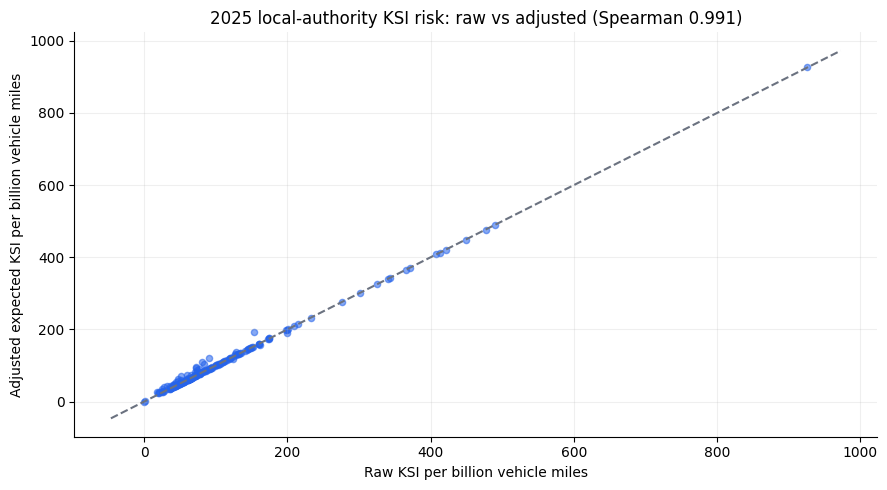

{'authorities': 208, 'spearman_rank_correlation': np.float64(0.9913)}

In [6]:
latest=covered[covered.collision_year==2025].copy()
rho=spearmanr(latest.raw_ksi_per_billion_vehicle_miles,latest.adjusted_ksi_per_billion_vehicle_miles).statistic
ax=latest.plot.scatter(x='raw_ksi_per_billion_vehicle_miles',y='adjusted_ksi_per_billion_vehicle_miles',color=BLUE,alpha=.55)
lo=min(ax.get_xlim()[0],ax.get_ylim()[0]); hi=max(ax.get_xlim()[1],ax.get_ylim()[1]); ax.plot([lo,hi],[lo,hi],color=GREY,linestyle='--')
ax.set(title=f'2025 local-authority KSI risk: raw vs adjusted (Spearman {rho:.3f})',xlabel='Raw KSI per billion vehicle miles',ylabel='Adjusted expected KSI per billion vehicle miles')
plt.tight_layout(); plt.show()
{'authorities':len(latest),'spearman_rank_correlation':round(rho,4)}

## Takeaways

1. The Power BI model provides raw and adjusted KSI rates based on local-authority vehicle miles.
2. The adjusted metric is the default comparison measure, with the raw metric retained for transparency and sensitivity checks.
3. AADF contributes sample-coverage and quality flags only; no absolute link-level risk measure is created before road-segment geometry is available.
4. The star schema contains `fact_collision`, `fact_local_authority_year_risk`, `fact_exposure_sensitivity`, and conformed date, LSOA, local-authority, and scenario dimensions.